# 02 – E0: Baseline (CNN pequeña)
**Pregunta que responde:** ¿qué se consigue sin una arquitectura sofisticada ni preentrenamiento?

**Diseño:** red convolucional pequeña de 3 bloques, entrenada desde cero con los mismos datos,
semilla, tamaño de imagen y presupuesto de épocas que los demás experimentos.

> **Hipótesis E0** (copiarla aquí desde `protocolo.md` ANTES de ejecutar):
> Creemos que la CNN pequeña entrenada desde cero aprenderá sobre todo a reconocer la clase mayoritaria (CMD) y tendrá F1 bajo en las clases con pocas imágenes (healthy y CBB), porque 5.656 imágenes son pocas para aprender desde cero rasgos finos como manchas y moteados. Lo veremos si el accuracy queda claramente por encima del macro-F1 y si la matriz de confusión concentra predicciones en CMD.

In [ ]:
# ============================================================
# CONFIGURACIÓN DEL PROTOCOLO (igual en todos los notebooks)
# ============================================================
import os, time, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

SEED = 42          # semilla fija -> resultados reproducibles
IMG = 224          # tamaño de entrada estándar de MobileNetV2 / ResNet
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)   # fija la semilla de Python, NumPy y TensorFlow
os.makedirs("results", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Instalar dependencia requerida por tensorflow-datasets en este entorno
!pip install -q importlib_resources

# ============================================================
# CARGA DEL DATASET (particiones oficiales de TFDS)
# ============================================================
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    as_supervised=True,      # devuelve pares (imagen, etiqueta)
    with_info=True,
)
CLASES = info.features["label"].names   # ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
N_CLASES = len(CLASES)
print("Clases:", CLASES)
print("Train:", info.splits["train"].num_examples,
      "| Val:", info.splits["validation"].num_examples,
      "| Test:", info.splits["test"].num_examples)

Clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Train: 5656 | Val: 1889 | Test: 1885


In [ ]:
# ============================================================
# ELIMINAR DUPLICADOS Y ETIQUETAS CONTRADICTORIAS (evita fuga de datos)
# ============================================================
# EDA: imágenes idénticas repetidas dentro y entre particiones
# (10 de prueba también estaban en entrenamiento) y 18 imágenes repetidas
# con ETIQUETAS DISTINTAS (ruido de etiquetado).
# Criterio:
#   1) Toda imagen cuya huella (MD5) aparece con más de una etiqueta se quita de todas las particiones.
#   2) Se recorre train -> validation -> test y se quita toda imagen ya vista.
def huellas_etiquetas(ds):
    return [(hashlib.md5(img.tobytes()).hexdigest(), int(y)) for img, y in tfds.as_numpy(ds)]

parts = {"train": ds_train, "validation": ds_val, "test": ds_test}
he = {p: huellas_etiquetas(d) for p, d in parts.items()}

etiquetas_por_huella = {}
for p in he:
    for hh, y in he[p]:
        etiquetas_por_huella.setdefault(hh, set()).add(y)
contradictorias = {hh for hh, ys in etiquetas_por_huella.items() if len(ys) > 1}
print("Huellas con etiquetas contradictorias:", len(contradictorias))

vistos, mascaras = set(), {}
for p in ["train", "validation", "test"]:
    keep = []
    for hh, _ in he[p]:
        keep.append(hh not in vistos and hh not in contradictorias)
        vistos.add(hh)
    mascaras[p] = np.array(keep)
    print(f"{p}: se excluyen {(~mascaras[p]).sum()} -> quedan {mascaras[p].sum()}")

def filtrar(ds, keep):
    keep_t = tf.constant(keep)
    return (ds.enumerate()
              .filter(lambda i, xy: tf.gather(keep_t, i))
              .map(lambda i, xy: xy))

ds_train = filtrar(ds_train, mascaras["train"])
ds_val = filtrar(ds_val, mascaras["validation"])
ds_test = filtrar(ds_test, mascaras["test"])

with open("results/indices_excluidos_final.json", "w") as f:
    json.dump({p: np.where(~m)[0].tolist() for p, m in mascaras.items()}, f)

Huellas con etiquetas contradictorias: 18
train: se excluyen 36 -> quedan 5620
validation: se excluyen 13 -> quedan 1876
test: se excluyen 11 -> quedan 1874


In [ ]:
# ============================================================
# PIPELINE: redimensionar a 224x224, guardar en caché, agrupar en lotes
# ============================================================
# - Se redimensiona y se guarda en uint8 (0-255) para ahorrar memoria.
# - La normalización NO se hace aquí: va dentro de cada modelo,
#   porque cada backbone espera una escala distinta.
# - Solo el entrenamiento se baraja. Validación y prueba mantienen su orden
#   (así las etiquetas reales coinciden con las predicciones).
# - NO hay augmentation en validación ni prueba.
def preparar(ds, entrenamiento=False):
    ds = ds.map(lambda x, y: (tf.cast(tf.image.resize(x, (IMG, IMG)), tf.uint8), y),
                num_parallel_calls=AUTOTUNE).cache()
    if entrenamiento:
        ds = ds.shuffle(2000, seed=SEED)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y),
                             num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train = preparar(ds_train, entrenamiento=True)
val = preparar(ds_val)
test = preparar(ds_test)

# Etiquetas reales de validación y prueba (en el mismo orden que las predicciones)
y_val = np.concatenate([y.numpy() for _, y in val])
y_test = np.concatenate([y.numpy() for _, y in test])
print("Etiquetas val:", y_val.shape, "| test:", y_test.shape)

Etiquetas val: (1876,) | test: (1874,)


In [ ]:
# ============================================================
# FUNCIONES DE EVALUACIÓN (las mismas para todos los experimentos)
# ============================================================
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

def evaluar(model, ds, y_true, nombre, particion):
    """Calcula métricas, guarda la matriz de confusión y devuelve un diccionario."""
    t0 = time.time()
    probs = model.predict(ds, verbose=0)
    t_inf = time.time() - t0
    y_pred = probs.argmax(axis=1)

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    reporte = classification_report(y_true, y_pred, target_names=CLASES,
                                    digits=3, output_dict=True, zero_division=0)

    print(f"\n===== {nombre} – {particion} =====")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {macro_f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=CLASES, digits=3, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{nombre} – matriz de confusión ({particion})")
    plt.tight_layout()
    plt.savefig(f"results/{nombre}_matriz_{particion}.png", dpi=120)
    plt.show()

    # Se guardan las predicciones para poder recalcular métricas sin reentrenar
    np.save(f"results/{nombre}_ypred_{particion}.npy", y_pred)
    np.save(f"results/{nombre}_probs_{particion}.npy", probs)

    return {
        "accuracy": round(float(acc), 4),
        "macro_f1": round(float(macro_f1), 4),
        "f1_por_clase": {c: round(reporte[c]["f1-score"], 4) for c in CLASES},
        "recall_por_clase": {c: round(reporte[c]["recall"], 4) for c in CLASES},
        "inferencia_ms_por_imagen": round(1000 * t_inf / len(y_true), 3),
    }

def graficar_curvas(hist, nombre):
    """Curvas de entrenamiento vs validación: sirven para ver sobreajuste."""
    h = hist.history
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    axs[0].plot(h["loss"], label="entrenamiento"); axs[0].plot(h["val_loss"], label="validación")
    axs[0].set_title("Pérdida (loss)"); axs[0].set_xlabel("época"); axs[0].legend()
    axs[1].plot(h["accuracy"], label="entrenamiento"); axs[1].plot(h["val_accuracy"], label="validación")
    axs[1].set_title("Accuracy"); axs[1].set_xlabel("época"); axs[1].legend()
    fig.suptitle(nombre); plt.tight_layout()
    plt.savefig(f"results/{nombre}_curvas.png", dpi=120)
    plt.show()

def tamano_modelo_mb(model, nombre):
    ruta = f"results/{nombre}.keras"
    model.save(ruta)
    return round(os.path.getsize(ruta) / 1e6, 2)

## Modelo E0
- `Rescaling(1/255)`: lleva los píxeles de 0–255 a 0–1.
- 3 bloques **Conv2D + MaxPooling**: aprenden patrones (bordes → texturas → manchas).
- `GlobalAveragePooling2D`: resume cada mapa de características en un número.
- `Dropout(0.3)`: apaga neuronas al azar para reducir sobreajuste.
- `Dense(5, softmax)`: da una probabilidad para cada una de las 5 clases.

In [ ]:
NOMBRE = "E0_baseline"
EPOCHS = 10        # mismo presupuesto máximo que E1
LR = 1e-3

def construir_e0():
    entradas = tf.keras.Input(shape=(IMG, IMG, 3))
    x = tf.keras.layers.Rescaling(1.0 / 255)(entradas)
    for filtros in (32, 64, 128):
        x = tf.keras.layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    salidas = tf.keras.layers.Dense(N_CLASES, activation="softmax")(x)
    return tf.keras.Model(entradas, salidas, name=NOMBRE)

model = construir_e0()
model.compile(optimizer=tf.keras.optimizers.Adam(LR),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "E0_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,893 (366.77 KB)

 Trainable params: 93,893 (366.77 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento
`EarlyStopping` detiene el entrenamiento si la pérdida de **validación** no mejora en 3 épocas
y recupera los mejores pesos. La prueba nunca se usa para decidir nada.

In [ ]:
parar = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

t0 = time.time()
hist = model.fit(train, validation_data=val, epochs=EPOCHS, callbacks=[parar])
t_entrenamiento = time.time() - t0
print(f"\nTiempo de entrenamiento: {t_entrenamiento / 60:.1f} min | épocas ejecutadas: {len(hist.history['loss'])}")

Epoch 1/10
    176/Unknown 43s 134ms/step - accuracy: 0.4590 - loss: 1.3511

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


176/176 ━━━━━━━━━━━━━━━━━━━━ 50s 176ms/step - accuracy: 0.4699 - loss: 1.3285 - val_accuracy: 0.4712 - val_loss: 1.2840
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - accuracy: 0.5222 - loss: 1.2419 - val_accuracy: 0.5634 - val_loss: 1.1818
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.5648 - loss: 1.1822 - val_accuracy: 0.6087 - val_loss: 1.1763
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - accuracy: 0.5870 - loss: 1.1515 - val_accuracy: 0.6194 - val_loss: 1.0862
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - accuracy: 0.5979 - loss: 1.1221 - val_accuracy: 0.5816 - val_loss: 1.1097
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.6011 - loss: 1.1043 - val_accuracy: 0.6135 - val_loss: 1.0651
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 20s 62ms/step - accuracy: 0.6009 - loss: 1.1097 - val_accuracy: 0.6237 - val_loss: 1.0585
Epoch 8/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.6107 - loss: 1.0896 - val_accura

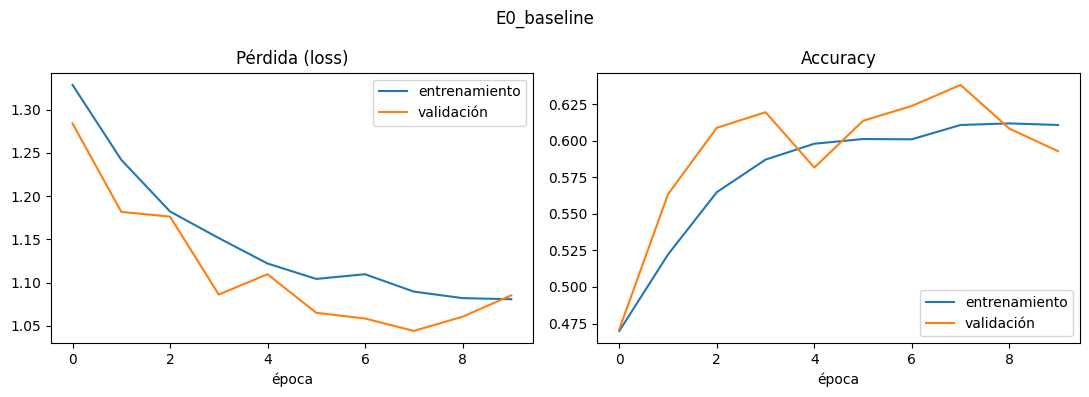

In [ ]:
graficar_curvas(hist, NOMBRE)

## Evaluación
Se reporta validación (para analizar) y prueba (para la tabla comparativa final E0–E3).


===== E0_baseline – validacion =====
Accuracy: 0.6381 | Macro-F1: 0.3062
              precision    recall  f1-score   support

         cbb      0.571     0.053     0.097       151
        cbsd      0.567     0.762     0.650       478
         cgm      0.000     0.000     0.000       257
         cmd      0.676     0.933     0.784       884
     healthy      0.000     0.000     0.000       106

    accuracy                          0.638      1876
   macro avg      0.363     0.350     0.306      1876
weighted avg      0.509     0.638     0.543      1876



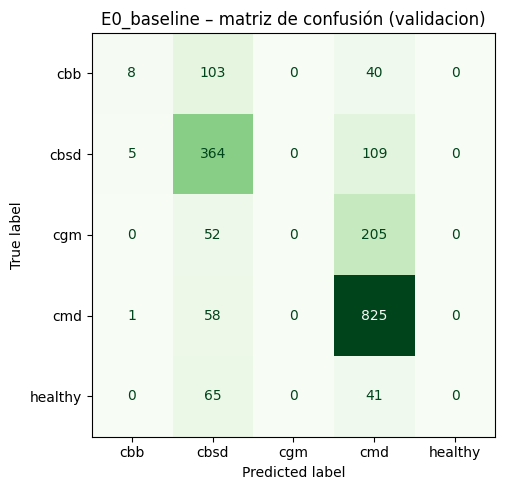

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



===== E0_baseline – prueba =====
Accuracy: 0.6275 | Macro-F1: 0.2994
              precision    recall  f1-score   support

         cbb      0.667     0.052     0.096       154
        cbsd      0.540     0.729     0.621       476
         cgm      0.000     0.000     0.000       253
         cmd      0.673     0.927     0.780       886
     healthy      0.000     0.000     0.000       105

    accuracy                          0.628      1874
   macro avg      0.376     0.342     0.299      1874
weighted avg      0.510     0.628     0.534      1874



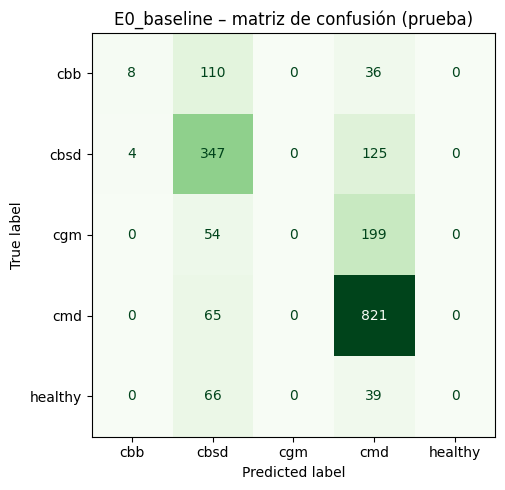

In [ ]:
res_val = evaluar(model, val, y_val, NOMBRE, "validacion")
res_test = evaluar(model, test, y_test, NOMBRE, "prueba")

In [ ]:
resultado = {
    "experimento": NOMBRE,
    "config": {"seed": SEED, "img": IMG, "batch": BATCH, "epochs_max": EPOCHS,
               "epochs_ejecutadas": len(hist.history["loss"]), "optimizador": "Adam", "lr": LR},
    "parametros": int(model.count_params()),
    "tamano_mb": tamano_modelo_mb(model, NOMBRE),
    "tiempo_entrenamiento_min": round(t_entrenamiento / 60, 2),
    "validacion": res_val,
    "prueba": res_test,
}
with open(f"results/{NOMBRE}.json", "w") as f:
    json.dump(resultado, f, indent=2)
print(json.dumps(resultado, indent=2))

{
  "experimento": "E0_baseline",
  "config": {
    "seed": 42,
    "img": 224,
    "batch": 32,
    "epochs_max": 10,
    "epochs_ejecutadas": 10,
    "optimizador": "Adam",
    "lr": 0.001
  },
  "parametros": 93893,
  "tamano_mb": 1.18,
  "tiempo_entrenamiento_min": 2.97,
  "validacion": {
    "accuracy": 0.6381,
    "macro_f1": 0.3062,
    "f1_por_clase": {
      "cbb": 0.097,
      "cbsd": 0.65,
      "cgm": 0.0,
      "cmd": 0.7842,
      "healthy": 0.0
    },
    "recall_por_clase": {
      "cbb": 0.053,
      "cbsd": 0.7615,
      "cgm": 0.0,
      "cmd": 0.9333,
      "healthy": 0.0
    },
    "inferencia_ms_por_imagen": 1.118
  },
  "prueba": {
    "accuracy": 0.6275,
    "macro_f1": 0.2994,
    "f1_por_clase": {
      "cbb": 0.0964,
      "cbsd": 0.6208,
      "cgm": 0.0,
      "cmd": 0.7797,
      "healthy": 0.0
    },
    "recall_por_clase": {
      "cbb": 0.0519,
      "cbsd": 0.729,
      "cgm": 0.0,
      "cmd": 0.9266,
      "healthy": 0.0
    },
    "inferencia_ms_por

Errores en validación: 679 de 1876


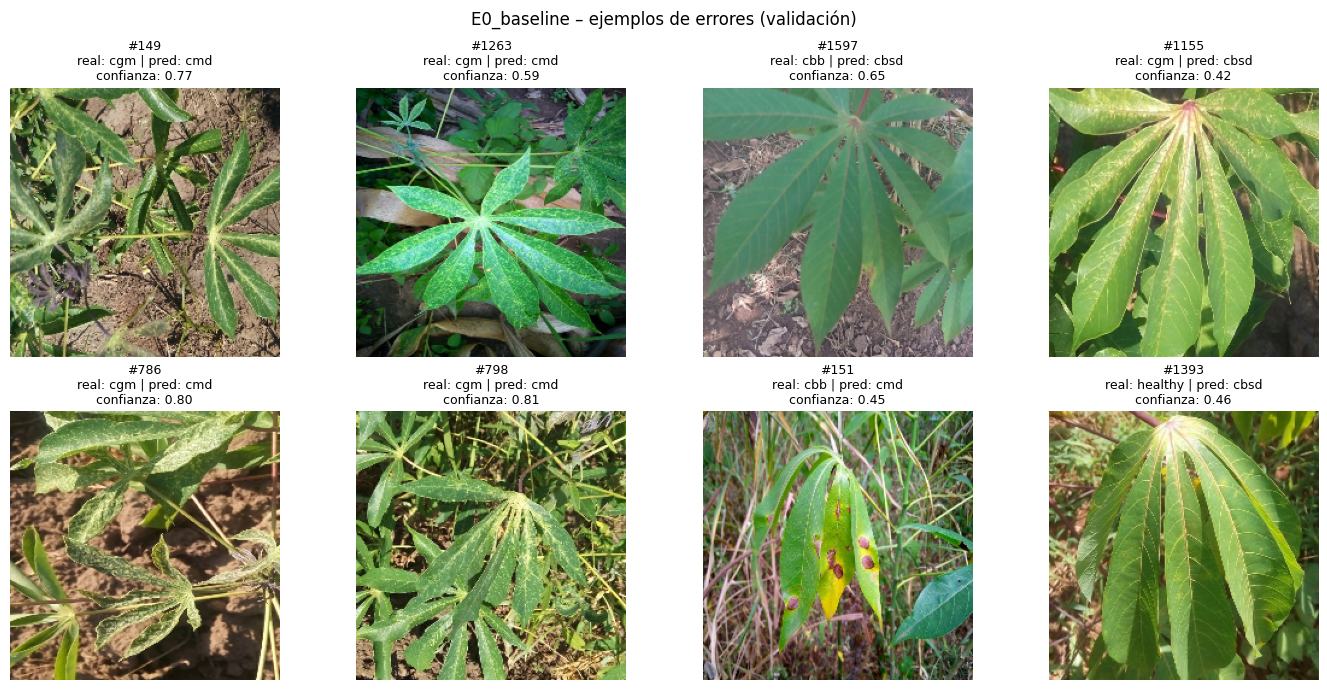

Índices mostrados: [149, 1263, 1597, 1155, 786, 798, 151, 1393]


In [ ]:
# ============================================================
# INSPECCIÓN DE ERRORES (en VALIDACIÓN, no en prueba)
# ============================================================
# Se muestran imágenes mal clasificadas con la clase real, la predicha y la confianza.
# Ustedes deben mirarlas y anotar en registro_errores.md por qué creen que falló.
x_val_img = np.concatenate([x.numpy().astype("uint8") for x, _ in val])
probs_val = np.load(f"results/{NOMBRE}_probs_validacion.npy")
pred_val = probs_val.argmax(axis=1)

errores = np.where(pred_val != y_val)[0]
print(f"Errores en validación: {len(errores)} de {len(y_val)}")

rng = np.random.default_rng(SEED)
muestra = rng.choice(errores, size=min(8, len(errores)), replace=False)

fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axs.ravel(), muestra):
    ax.imshow(x_val_img[i]); ax.axis("off")
    ax.set_title(f"#{i}\nreal: {CLASES[y_val[i]]} | pred: {CLASES[pred_val[i]]}\n"
                 f"confianza: {probs_val[i].max():.2f}", fontsize=9)
plt.suptitle(f"{NOMBRE} – ejemplos de errores (validación)")
plt.tight_layout()
plt.savefig(f"results/{NOMBRE}_errores.png", dpi=120)
plt.show()
print("Índices mostrados:", muestra.tolist())

## Análisis E0

**Resultados (validación, 1.876 imágenes):** accuracy 0,638 · macro-F1 0,306 · 2,97 min de entrenamiento · 93.893 parámetros (1,18 MB) · 1,1 ms por imagen. En prueba: accuracy 0,628 y macro-F1 0,299, coherentes con validación.

**¿Se cumplió la hipótesis?** Sí. El accuracy (0,64) duplica el macro-F1 (0,31): el modelo acierta sobre todo la clase mayoritaria. Un modelo que dijera siempre CMD tendría ≈0,47 de accuracy, así que E0 sí aprendió algo, pero solo para dos clases.

**Por clase:** CMD tiene F1 0,78 (recall 0,93) y CBSD 0,65; CBB apenas 0,10, y CGM y healthy 0,00: **el modelo nunca predice esas dos clases**. De 1.876 predicciones, 1.220 son CMD y 642 CBSD. Las clases que fallan son las de menos imágenes (healthy 5,6 %, CBB 8,2 %), pero CGM (13,7 %) también falla por parecerse visualmente a CMD.

**Matriz de confusión:** la confusión dominante es **CGM → CMD** (205 de 257). También CBB → CBSD (103 de 151) y healthy → CBSD/CMD (65 y 41).

**Curvas:** la pérdida de entrenamiento y la de validación bajan juntas y el accuracy de entrenamiento se estanca en ≈0,61. **No hay sobreajuste sino subajuste**: la red pequeña no tiene capacidad para aprender rasgos finos (moteados, manchas pequeñas) desde cero con ≈5.600 imágenes. La validación oscila entre épocas; los mejores pesos (época 8) se restauraron al final.

**Errores revisados:** ver `registro_errores.md`. Patrones: el moteado de CGM se confunde con el mosaico; nervaduras claras se confunden con el rayado de CBSD; casi todas las fotos tienen suelo y malezas de fondo; varios errores ocurren con confianza alta (≈0,8).

**Conclusión:** E0 marca el punto de partida: macro-F1 ≈0,31. Para justificar la transferencia, E1 debe mejorar sobre todo en CGM, CBB y healthy, no solo en accuracy.

Macro-F1 validación (recalculado): 0.3062
Accuracy validación (recalculado): 0.6381


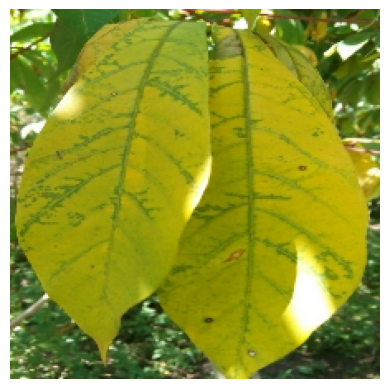

Clase real: cbsd
  cbb      0.613
  cbsd     0.386
  healthy  0.000
  cgm      0.000
  cmd      0.000
Predicción: cbb


In [ ]:
# ============================================================
# PARA LA REVISIÓN EN VIVO
# ============================================================
# (a) Recalcular el macro-F1 desde las predicciones guardadas, sin reentrenar
yp = np.load(f"results/{NOMBRE}_ypred_validacion.npy")
print("Macro-F1 validación (recalculado):", round(f1_score(y_val, yp, average="macro"), 4))
print("Accuracy validación (recalculado):", round(accuracy_score(y_val, yp), 4))

# (b) Predecir una sola imagen
def predecir_imagen(img_uint8):
    x = tf.image.resize(img_uint8, (IMG, IMG))[None, ...]     # agrega dimensión de lote
    p = model.predict(x, verbose=0)[0]
    for c, v in sorted(zip(CLASES, p), key=lambda t: -t[1]):
        print(f"  {c:8s} {v:.3f}")
    return CLASES[int(p.argmax())]

i = 0   # cambiar el índice para probar otra imagen de validación
plt.imshow(x_val_img[i]); plt.axis("off"); plt.show()
print("Clase real:", CLASES[y_val[i]])
print("Predicción:", predecir_imagen(x_val_img[i]))

# (c) Para probar con una foto propia en Colab:
# from google.colab import files
# subida = files.upload()
# ruta = list(subida.keys())[0]
# img = tf.keras.utils.img_to_array(tf.keras.utils.load_img(ruta)).astype("uint8")
# print(predecir_imagen(img))

In [ ]:
# ============================================================
# DESCARGAR LOS RESULTADOS PARA SUBIRLOS A GITHUB (carpeta results/)
# ============================================================
# Los archivos .keras pesan; súbanlos solo si GitHub los acepta (<100 MB).
!zip -r -q results_E0.zip results
from google.colab import files
files.download("results_E0.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>